# Báo Cáo Thực Nghiệm: Mạng Tích Chập 1D (1D CNN) Thuần NumPy Cho Bài Toán Hồi Quy
## Bài Toán: Dự Đoán Giá Nhà (Real Estate Continuous Price Regression)
**Học phần:** Phát triển Hệ thống Thông minh (Intelligent System Development)  
**Nhiệm vụ:** Assignment 04 - Xây dựng mô hình 1D CNN hồi quy với nơ-ron đầu ra tuyến tính (Linear Output) thuần từ đầu  
**Dữ liệu:** `usa_real_estate_150k.csv` (150,000 giao dịch bất động sản)


In [1]:
import os
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.size'] = 11


### 1. Đọc Dữ Liệu & Khảo Sát Cấu Trúc
Tập dữ liệu gồm 150,000 bản ghi bất động sản với các thuộc tính diện tích, số phòng, diện tích đất và giá bán.


In [2]:
DATA_PATH = "../../../Assigment 02/house_price/data/usa_real_estate_150k.csv"
if not os.path.exists(DATA_PATH):
    DATA_PATH = "src/Assigment 02/house_price/data/usa_real_estate_150k.csv"

df_raw = pd.read_csv(DATA_PATH)
print(f"Kích thước tập dữ liệu thô: {df_raw.shape[0]:,} dòng, {df_raw.shape[1]} cột")
df_raw.head()


Kích thước tập dữ liệu thô: 150,000 dòng, 12 cột


,brokered_by,status,price,bed,bath,acre_lot,street,city,state,zip_code,house_size,prev_sold_date
0,103378.0,for_sale,105000.0,3.0,2.0,0.12,1962661.0,Adjuntas,Puerto Rico,601.0,920.0,NaN
1,52707.0,for_sale,80000.0,4.0,2.0,0.08,1902874.0,Adjuntas,Puerto Rico,601.0,1527.0,NaN
2,103379.0,for_sale,67000.0,2.0,1.0,0.15,1404990.0,Juana Diaz,Puerto Rico,795.0,748.0,NaN
3,31239.0,for_sale,145000.0,4.0,2.0,0.10,1947675.0,Ponce,Puerto Rico,731.0,1800.0,NaN
4,103378.0,for_sale,179000.0,4.0,3.0,0.46,1850806.0,San Sebastian,Puerto Rico,612.0,2520.0,NaN


### 2. Quy Trình Tiền Xử Lý & Kỹ Thuật Tạo Đặc Trưng
1. Xử lý giá trị khuyết thiếu và ngoại lai (lọc giá từ $10,000 đến $5,000,000; diện tích 200 - 20,000 sqft).
2. Tạo 8 đặc trưng cấu trúc bất động sản chuẩn hóa:
   - `log_house_size` = log(house_size)
   - `bed` = số phòng ngủ
   - `bath` = số phòng tắm
   - `total_rooms` = bed + bath
   - `bed_bath_prod` = bed * bath
   - `sqft_per_room` = house_size / (total_rooms + 1)
   - `bath_bed_ratio` = bath / (bed + 1)
   - `log_acre_lot` = log1p(acre_lot)
3. Biến mục tiêu: `log_price` = log(price) để ổn định phân phối giá trị.


In [3]:
df_clean = df_raw.dropna(subset=['price', 'house_size', 'bed', 'bath']).copy()
df_clean = df_clean[(df_clean['price'] >= 10000) & (df_clean['price'] <= 5000000)]
df_clean = df_clean[(df_clean['house_size'] >= 200) & (df_clean['house_size'] <= 20000)]

# Tạo 8 đặc trưng
df_clean['log_house_size'] = np.log(df_clean['house_size'])
df_clean['total_rooms'] = df_clean['bed'] + df_clean['bath']
df_clean['bed_bath_prod'] = df_clean['bed'] * df_clean['bath']
df_clean['sqft_per_room'] = df_clean['house_size'] / (df_clean['total_rooms'] + 1)
df_clean['bath_bed_ratio'] = df_clean['bath'] / (df_clean['bed'] + 1)
df_clean['log_acre_lot'] = np.log1p(df_clean['acre_lot'].fillna(df_clean['acre_lot'].median()))
df_clean['log_price'] = np.log(df_clean['price'])

features = ['log_house_size', 'bed', 'bath', 'total_rooms', 'bed_bath_prod', 'sqft_per_room', 'bath_bed_ratio', 'log_acre_lot']

X_data = df_clean[features].values.astype(np.float32)
y_data = df_clean['log_price'].values.astype(np.float32)

print(f"Dữ liệu sau làm sạch: {X_data.shape[0]:,} mẫu, {X_data.shape[1]} đặc trưng.")


Dữ liệu sau làm sạch: 150,000 mẫu, 8 đặc trưng.


### 3. Phân Chia Dữ Liệu & Chuẩn Hóa
- Tỷ lệ Train/Test: 80% / 20% với `random_state=42`.
- Chuẩn hóa cả đặc trưng `X` và nhãn hồi quy `y` bằng `StandardScaler`.


In [4]:
X_train_raw, X_test_raw, y_train_log, y_test_log = train_test_split(
    X_data, y_data, test_size=0.20, random_state=RANDOM_SEED
)

scaler_x = StandardScaler()
X_train_scaled = scaler_x.fit_transform(X_train_raw)
X_test_scaled = scaler_x.transform(X_test_raw)

scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train_log.reshape(-1, 1)).ravel()
y_test_scaled = scaler_y.transform(y_test_log.reshape(-1, 1)).ravel()

# Định dạng 3D: (N, C_in=1, L=8)
X_train = X_train_scaled[:, np.newaxis, :]
X_test = X_test_scaled[:, np.newaxis, :]

print(f"X_train: {X_train.shape}, y_train: {y_train_scaled.shape}")
print(f"X_test : {X_test.shape}, y_test : {y_test_scaled.shape}")


X_train: (120000, 1, 8), y_train: (120000,)
X_test : (30000, 1, 8), y_test : (30000,)


### 4. Triển Khai Toàn Bộ Các Lớp 1D CNN Hồi Quy Thuần Từ Đầu (NumPy From Scratch)
Dưới đây là cài đặt chi tiết toàn bộ các lớp tích chập, gom mẫu, kích hoạt, kết nối đầy đủ và bộ tối ưu hóa Adam theo đúng lý thuyết Bài giảng số 4 cho bài toán hồi quy (Slide 27 & 28):
1. **`Conv1D`**: Phép tích chập 1D qua các kênh đầu vào bằng kỹ thuật `sliding_window_view` và `np.einsum`, tính đạo hàm giải tích `dW`, `db`, `dX`.
2. **`MaxPool1D`**: Gom mẫu cực đại 1 chiều và truyền ngược gradient qua mặt nạ argmax.
3. **`ReLU`, `Flatten`, `Dense`**: Khối hàm kích hoạt, trải phẳng và tầng tuyến tính.
4. **`Sequential1DCNN`**: Container quản lý chuỗi các tầng.
5. **`AdamOptimizer`**: Thuật toán tối ưu thích nghi Adam cập nhật trọng số và bias.
6. **`mean_squared_error`**: Hàm mất mát MSE cùng đạo hàm giải tích cho bài toán hồi quy continuous output.


In [5]:
# =====================================================================
# 1. CÀI ĐẶT CÁC LỚP MẠNG 1D CNN THUẦN TỪ ĐẦU BẰNG NUMPY
# =====================================================================

class Conv1D:
    def __init__(self, in_channels, out_channels, kernel_size=3, stride=1, padding=0):
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.kernel_size = kernel_size
        self.stride = stride
        self.padding = padding

        # Khởi tạo He (Kaiming) Normal
        limit = np.sqrt(2.0 / (in_channels * kernel_size))
        self.W = np.random.randn(out_channels, in_channels, kernel_size).astype(np.float32) * limit
        self.b = np.zeros(out_channels, dtype=np.float32)

        self.dW = np.zeros_like(self.W)
        self.db = np.zeros_like(self.b)
        self.X = None
        self.sub_windows = None

    def forward(self, X):
        # X shape: (batch_size, in_channels, length)
        # Output shape: (batch_size, out_channels, length_out)
        self.X = X
        batch_size, in_channels, length = X.shape
        assert in_channels == self.in_channels, f"Expected {self.in_channels} channels, got {in_channels}"

        if self.padding > 0:
            X_pad = np.pad(X, ((0, 0), (0, 0), (self.padding, self.padding)), mode='constant')
        else:
            X_pad = X

        # Sử dụng sliding_window_view vector hóa tối đa
        self.sub_windows = np.lib.stride_tricks.sliding_window_view(
            X_pad, window_shape=self.kernel_size, axis=-1
        )[:, :, ::self.stride, :]

        # Einsum: N: batch, C: in_channels, L: out_len, K: kernel_size; F: out_channels
        out = np.einsum('nclk,fck->nfl', self.sub_windows, self.W) + self.b[:, None]
        return out

    def backward(self, dZ):
        # dZ shape: (batch_size, out_channels, length_out)
        # Returns dX shape: (batch_size, in_channels, length)
        self.db = np.sum(dZ, axis=(0, 2))
        self.dW = np.einsum('nfl,nclk->fck', dZ, self.sub_windows)

        batch_size, in_channels, length = self.X.shape
        L_out = dZ.shape[2]
        dX = np.zeros_like(self.X)

        for k in range(self.kernel_size):
            dX[:, :, k:k + L_out] += np.einsum('nfl,fc->ncl', dZ, self.W[:, :, k])

        return dX


class MaxPool1D:
    def __init__(self, pool_size=2):
        self.pool_size = pool_size
        self.X_shape = None
        self.X_reshaped = None
        self.out = None

    def forward(self, X):
        self.X_shape = X.shape
        batch_size, channels, length = X.shape
        L_out = length // self.pool_size

        self.X_reshaped = X[:, :, :L_out * self.pool_size].reshape(
            batch_size, channels, L_out, self.pool_size
        )
        self.out = np.max(self.X_reshaped, axis=-1)
        return self.out

    def backward(self, dZ):
        batch_size, channels, L_out = dZ.shape
        argmax_mask = (self.X_reshaped == self.out[:, :, :, None])
        counts = np.sum(argmax_mask, axis=-1, keepdims=True)
        counts[counts == 0] = 1.0
        mask = argmax_mask / counts

        dX_reshaped = dZ[:, :, :, None] * mask
        dX = np.zeros(self.X_shape, dtype=dZ.dtype)
        dX[:, :, :L_out * self.pool_size] = dX_reshaped.reshape(
            batch_size, channels, L_out * self.pool_size
        )
        return dX


class ReLU:
    def __init__(self):
        self.X = None

    def forward(self, X):
        self.X = X
        return np.maximum(0, X)

    def backward(self, dZ):
        return dZ * (self.X > 0)


class Flatten:
    def __init__(self):
        self.orig_shape = None

    def forward(self, X):
        self.orig_shape = X.shape
        return X.reshape(X.shape[0], -1)

    def backward(self, dZ):
        return dZ.reshape(self.orig_shape)


class Dense:
    def __init__(self, in_features, out_features):
        self.in_features = in_features
        self.out_features = out_features

        limit = np.sqrt(2.0 / in_features)
        self.W = np.random.randn(in_features, out_features).astype(np.float32) * limit
        self.b = np.zeros(out_features, dtype=np.float32)

        self.dW = np.zeros_like(self.W)
        self.db = np.zeros_like(self.b)
        self.X = None

    def forward(self, X):
        self.X = X
        return np.dot(X, self.W) + self.b

    def backward(self, dZ):
        self.db = np.sum(dZ, axis=0)
        self.dW = np.dot(self.X.T, dZ)
        return np.dot(dZ, self.W.T)


class Sequential1DCNN:
    def __init__(self, layers):
        self.layers = layers

    def forward(self, X):
        out = X
        for layer in self.layers:
            out = layer.forward(out)
        return out

    def backward(self, dLoss):
        grad = dLoss
        for layer in reversed(self.layers):
            grad = layer.backward(grad)
        return grad

    def get_trainable_layers(self):
        return [l for l in self.layers if hasattr(l, 'W')]


class AdamOptimizer:
    def __init__(self, trainable_layers, lr=0.001, beta1=0.9, beta2=0.999, eps=1e-8):
        self.layers = trainable_layers
        self.lr = lr
        self.beta1 = beta1
        self.beta2 = beta2
        self.eps = eps
        self.t = 0

        self.mW = [np.zeros_like(l.W) for l in self.layers]
        self.vW = [np.zeros_like(l.W) for l in self.layers]
        self.mb = [np.zeros_like(l.b) if hasattr(l, 'b') else None for l in self.layers]
        self.vb = [np.zeros_like(l.b) if hasattr(l, 'b') else None for l in self.layers]

    def step(self):
        self.t += 1
        for i, layer in enumerate(self.layers):
            self.mW[i] = self.beta1 * self.mW[i] + (1 - self.beta1) * layer.dW
            self.vW[i] = self.beta2 * self.vW[i] + (1 - self.beta2) * (layer.dW ** 2)
            m_hat = self.mW[i] / (1 - self.beta1 ** self.t)
            v_hat = self.vW[i] / (1 - self.beta2 ** self.t)
            layer.W -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)

            if hasattr(layer, 'b') and hasattr(layer, 'db'):
                self.mb[i] = self.beta1 * self.mb[i] + (1 - self.beta1) * layer.db
                self.vb[i] = self.beta2 * self.vb[i] + (1 - self.beta2) * (layer.db ** 2)
                m_hat_b = self.mb[i] / (1 - self.beta1 ** self.t)
                v_hat_b = self.vb[i] / (1 - self.beta2 ** self.t)
                layer.b -= self.lr * m_hat_b / (np.sqrt(v_hat_b) + self.eps)


def mse_loss(y_pred, y_true):
    diff = y_pred - y_true
    loss = np.mean(diff ** 2)
    grad = (2.0 * diff) / len(y_true)
    return loss, grad

print("Đã nạp toàn bộ các lớp 1D CNN Hồi quy thuần NumPy thành công!")


Đã nạp toàn bộ các lớp 1D CNN Hồi quy thuần NumPy thành công!


### 5. Khởi Tạo Kiến Trúc Mô Hình & Kiểm Tra Tham Số
Khởi tạo cấu trúc theo Slide 27 & 28:
`Input (1, 8) -> Conv1D(16, k=3) -> ReLU -> Conv1D(32, k=3) -> ReLU -> MaxPool1D(2) -> Flatten -> Dense(16) -> ReLU -> Dense(1)`.
*Lưu ý: Tầng cuối Dense(1) là đầu ra tuyến tính (không qua Sigmoid).*


In [6]:
model = Sequential1DCNN([
    Conv1D(in_channels=1, out_channels=16, kernel_size=3), # L_out = 8 - 3 + 1 = 6
    ReLU(),
    Conv1D(in_channels=16, out_channels=32, kernel_size=3), # L_out = 6 - 3 + 1 = 4
    ReLU(),
    MaxPool1D(pool_size=2),                                  # L_out = 4 // 2 = 2
    Flatten(),                                               # 32 * 2 = 64
    Dense(in_features=64, out_features=16),
    ReLU(),
    Dense(in_features=16, out_features=1)                   # Nơ-ron tuyến tính (Linear Output)
])

trainable_layers = model.get_trainable_layers()
total_params = sum(l.W.size + l.b.size for l in trainable_layers)
print(f"Tổng số tham số học được của 1D CNN Hồi quy: {total_params:,} tham số")


Tổng số tham số học được của 1D CNN Hồi quy: 2,689 tham số


### 5. Huấn Luyện Mô Hình Hồi Quy


In [7]:
optimizer = AdamOptimizer(trainable_layers, lr=0.002)
epochs = 12
batch_size = 256
n_samples = len(X_train)

history = {"loss": [], "val_loss": [], "val_r2": []}

start_time = time.time()
print("Bắt đầu huấn luyện mô hình 1D CNN Hồi quy NumPy...")

for epoch in range(1, epochs + 1):
    indices = np.random.permutation(n_samples)
    X_shuffled = X_train[indices]
    y_shuffled = y_train_scaled[indices]
    
    epoch_losses = []
    for i in range(0, n_samples, batch_size):
        X_b = X_shuffled[i:i + batch_size]
        y_b = y_shuffled[i:i + batch_size, np.newaxis]
        
        preds = model.forward(X_b)
        loss, grad = mse_loss(preds, y_b)
        epoch_losses.append(loss)
        
        model.backward(grad)
        optimizer.step()
        
    train_loss = np.mean(epoch_losses)
    
    val_preds = model.forward(X_test).ravel()
    val_loss, _ = mse_loss(val_preds[:, np.newaxis], y_test_scaled[:, np.newaxis])
    val_r2 = r2_score(y_test_scaled, val_preds)
    
    history["loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_r2"].append(val_r2)
    
    print(f"Epoch {epoch:02d}/{epochs:02d} - Train MSE: {train_loss:.4f} | Val MSE: {val_loss:.4f} | Val R²: {val_r2:.4f}")

train_time = time.time() - start_time
print(f"\nHuấn luyện hoàn tất trong: {train_time:.2f} giây!")


Bắt đầu huấn luyện mô hình 1D CNN Hồi quy NumPy...


Epoch 01/12 - Train MSE: 0.7338 | Val MSE: 0.6305 | Val R²: 0.3706


Epoch 02/12 - Train MSE: 0.6243 | Val MSE: 0.6302 | Val R²: 0.3708


Epoch 03/12 - Train MSE: 0.6236 | Val MSE: 0.6294 | Val R²: 0.3717


Epoch 04/12 - Train MSE: 0.6216 | Val MSE: 0.6294 | Val R²: 0.3716


Epoch 05/12 - Train MSE: 0.6183 | Val MSE: 0.6250 | Val R²: 0.3761


... (3 outputs left out)

Epoch 09/12 - Train MSE: 0.6144 | Val MSE: 0.6357 | Val R²: 0.3654


Epoch 10/12 - Train MSE: 0.6109 | Val MSE: 0.6138 | Val R²: 0.3872


Epoch 11/12 - Train MSE: 0.6067 | Val MSE: 0.6142 | Val R²: 0.3868


Epoch 12/12 - Train MSE: 0.6049 | Val MSE: 0.6109 | Val R²: 0.3901

Huấn luyện hoàn tất trong: 197.15 giây!


### 6. Đánh Giá Toàn Diện Thang Đo Hồi Quy (MAE, RMSE, R²)
Quy đổi dự đoán về không gian giá trị thực ($ USD) để đánh giá thực tế.


=== KẾT QUẢ ĐÁNH GIÁ 1D CNN HỒI QUY (NUMPY FROM SCRATCH) ===
• R² Score (Log space)  : 0.3901
• RMSE (Log space)      : 0.6897
• MAE (Log space)       : 0.5204
• MAE (Thực tế USD)     : $290,959.57
• RMSE (Thực tế USD)    : $557,500.69
• Thời gian huấn luyện  : 197.15 giây


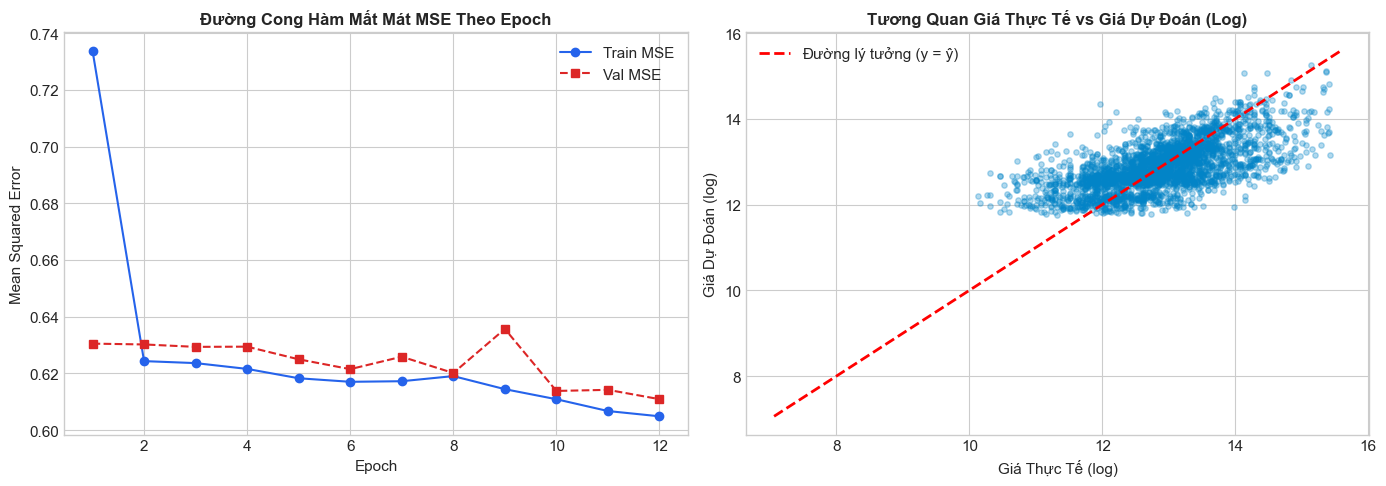

In [8]:
val_preds_scaled = model.forward(X_test).ravel()
val_preds_log = scaler_y.inverse_transform(val_preds_scaled.reshape(-1, 1)).ravel()

r2_val = r2_score(y_test_log, val_preds_log)
rmse_log = np.sqrt(mean_squared_error(y_test_log, val_preds_log))
mae_log = mean_absolute_error(y_test_log, val_preds_log)

# Quy đổi ra đơn vị tiền tệ $
y_test_dollars = np.exp(y_test_log)
preds_dollars = np.exp(val_preds_log)

mae_dollars = mean_absolute_error(y_test_dollars, preds_dollars)
rmse_dollars = np.sqrt(mean_squared_error(y_test_dollars, preds_dollars))

print(f"=== KẾT QUẢ ĐÁNH GIÁ 1D CNN HỒI QUY (NUMPY FROM SCRATCH) ===")
print(f"• R² Score (Log space)  : {r2_val:.4f}")
print(f"• RMSE (Log space)      : {rmse_log:.4f}")
print(f"• MAE (Log space)       : {mae_log:.4f}")
print(f"• MAE (Thực tế USD)     : ${mae_dollars:,.2f}")
print(f"• RMSE (Thực tế USD)    : ${rmse_dollars:,.2f}")
print(f"• Thời gian huấn luyện  : {train_time:.2f} giây")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(range(1, epochs + 1), history["loss"], 'o-', color='#2563eb', label='Train MSE')
axes[0].plot(range(1, epochs + 1), history["val_loss"], 's--', color='#dc2626', label='Val MSE')
axes[0].set_title('Đường Cong Hàm Mất Mát MSE Theo Epoch', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Mean Squared Error')
axes[0].legend()

# Scatter Actual vs Predicted
sample_idx = np.random.choice(len(y_test_log), size=3000, replace=False)
axes[1].scatter(np.asarray(y_test_log)[sample_idx], val_preds_log[sample_idx], alpha=0.3, color='#0284c7', s=15)
min_val = min(y_test_log.min(), val_preds_log.min())
max_val = max(y_test_log.max(), val_preds_log.max())
axes[1].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Đường lý tưởng (y = ŷ)')
axes[1].set_title('Tương Quan Giá Thực Tế vs Giá Dự Đoán (Log)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Giá Thực Tế (log)')
axes[1].set_ylabel('Giá Dự Đoán (log)')
axes[1].legend()

plt.tight_layout()
os.makedirs("../reports/figures", exist_ok=True)
plt.savefig("../reports/figures/01_house_price_numpy_results.png", dpi=300)
plt.show()


### 7. Lưu Trữ Kết Quả Để Đối Chuẩn


In [9]:
results_df = pd.DataFrame([{
    "Framework": "NumPy From Scratch",
    "Dataset": "House Price (150k)",
    "R2_Score": r2_val,
    "RMSE_Log": rmse_log,
    "MAE_Log": mae_log,
    "MAE_Dollars": mae_dollars,
    "Train_Time_Sec": train_time,
    "Epochs": epochs,
    "Batch_Size": batch_size
}])

os.makedirs("../reports", exist_ok=True)
results_df.to_csv("../reports/model_results_numpy.csv", index=False)
print("Đã lưu kết quả thành công vào ../reports/model_results_numpy.csv")
results_df


Đã lưu kết quả thành công vào ../reports/model_results_numpy.csv


,Framework,Dataset,R2_Score,RMSE_Log,MAE_Log,MAE_Dollars,Train_Time_Sec,Epochs,Batch_Size
0,NumPy From Scratch,House Price (150k),0.390118,0.68968,0.520435,290959.572268,197.148848,12,256
